# Exploration de `price_history`

**Auteur :** Emna (rôle : gestion de projet & documentation)
**Module :** Analyse financière — sprint en cours

## Objectifs

Ce notebook explore les données de marché stockées dans la table `price_history`
du simulateur de salle de marché. Conformément au cahier des charges, **aucun
modèle prédictif n'est entraîné ici** : on se contente de charger l'historique,
de calculer les indicateurs de base et de visualiser les séries pour préparer
la suite (modèle IA, agent de trading, analyse de sentiment).

On y calcule :
1. Les **rendements** (simple, log, cumulé) et leurs statistiques.
2. La **volatilité** annualisée (fenêtres 20 et 60 jours).
3. Le **RSI(14)** — *Relative Strength Index*, lissage de Wilder.
4. Les **moyennes mobiles** (SMA 20/50/200, EMA 12/26).
5. Le **MACD(12, 26, 9)**.
6. Une **matrice de corrélation** des rendements entre actifs.

## Pré-requis

Le projet doit tourner (Docker) et la base être peuplée :
```bash
docker compose up -d --build
docker compose exec backend alembic upgrade head
docker compose exec backend python -m app.seed
docker compose exec backend python -m app.import_prices   # ~4 min (limite plan gratuit)
```

Le notebook se lance **depuis la racine du projet** pour lire automatiquement
le fichier `.env` (et donc `DATABASE_URL`).


## 1. Configuration et connexion à la base

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sqlalchemy import create_engine, text

# Charge les variables du fichier .env à la racine du projet (DATABASE_URL, etc.).
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass  # python-dotenv n'est pas installé : on suppose DATABASE_URL déjà dans l'env

# Police par défaut gérant les accents français (DejaVu Sans est le défaut matplotlib).
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print("pandas", pd.__version__, "| numpy", np.__version__)


Matplotlib is building the font cache; this may take a moment.


pandas 3.1.1 | numpy 2.5.4


In [2]:
DATABASE_URL = os.environ.get("DATABASE_URL")

if not DATABASE_URL:
    raise RuntimeError(
        "DATABASE_URL est vide : lance ce notebook depuis la racine du projet "
        "(là où se trouve le fichier .env), ou définis DATABASE_URL manuellement."
    )

# Le backend force le pilote psycopg2 ; on fait pareil ici pour rester cohérent.
if DATABASE_URL.startswith("postgresql://"):
    DATABASE_URL = DATABASE_URL.replace("postgresql://", "postgresql+psycopg2://", 1)

engine = create_engine(DATABASE_URL, future=True)

# Vérification rapide : compte les lignes des deux tables concernées.
with engine.connect() as conn:
    n_assets = conn.execute(text("SELECT COUNT(*) FROM assets")).scalar()
    n_prices = conn.execute(text("SELECT COUNT(*) FROM price_history")).scalar()

print(f"DATABASE_URL : {DATABASE_URL.split('@')[-1]}")
print(f"Actifs en base       : {n_assets}")
print(f"Lignes price_history : {n_prices}")

if n_prices == 0:
    raise RuntimeError(
        "price_history est vide : lance `docker compose exec backend python -m app.import_prices`"
    )


DATABASE_URL : localhost:5432/salle_marche
Actifs en base       : 31
Lignes price_history : 8144


## 2. Chargement de `price_history`

On joint les cours à la table `assets` pour récupérer le symbole, le nom et le type d'actif. La requête est du SQL standard : elle fonctionne aussi bien sous PostgreSQL qu'ailleurs.

In [3]:
query = """
SELECT a.symbol, a.name, a.asset_type,
       p.date, p.open, p.high, p.low, p.close, p.volume
FROM price_history p
JOIN assets a ON a.id = p.asset_id
ORDER BY a.symbol, p.date
"""
df = pd.read_sql(query, engine, parse_dates=["date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)
print(df.shape)
df.head()


(8144, 9)


,symbol,name,asset_type,date,open,high,low,close,volume
0,AAPL,Apple Inc.,STOCK,2025-11-04,268.3300,271.4900,267.6200,270.0400,"49,274,800.0000"
1,AAPL,Apple Inc.,STOCK,2025-11-05,268.6100,271.7000,266.9300,270.1400,"43,683,100.0000"
2,AAPL,Apple Inc.,STOCK,2025-11-06,267.8900,273.4000,267.8900,269.7700,"51,204,000.0000"
3,AAPL,Apple Inc.,STOCK,2025-11-07,269.8000,272.2900,266.7700,268.4700,"48,227,400.0000"
4,AAPL,Apple Inc.,STOCK,2025-11-10,268.9600,273.7300,267.4600,269.4300,"41,312,400.0000"


## 3. Vue d'ensemble par actif

Pour chaque symbole : première et dernière séance disponibles, nombre de jours de cotation. Cela permet de repérer les actifs dont l'historique est incomplet (certains ADR/ETF récents ou manquants chez Twelve Data).

In [4]:
overview = (
    df.groupby(["symbol", "name", "asset_type"])
      .agg(premier_jour=("date", "min"),
           dernier_jour=("date", "max"),
           nb_seances=("date", "count"))
      .reset_index()
      .sort_values("symbol")
)
overview


,symbol,name,asset_type,premier_jour,dernier_jour,nb_seances
0,AAPL,Apple Inc.,STOCK,2025-11-04,2026-11-04,252
1,AMZN,"Amazon.com, Inc.",STOCK,2025-11-04,2026-11-04,252
2,ASML,"ASML Holding N.V. (Pays-Bas, ADR)",STOCK,2025-11-04,2026-11-04,252
3,DIA,SPDR Dow Jones Industrial Average ETF (indice ...,STOCK,2025-11-04,2026-11-04,252
4,EEM,iShares MSCI Emerging Markets ETF (marchés éme...,STOCK,2025-11-04,2026-11-04,252
5,EUR/USD,Euro / Dollar américain,FOREX,2025-11-04,2026-11-04,357
6,EWG,iShares MSCI Germany ETF (marché allemand),STOCK,2025-11-04,2026-11-04,252
7,EWJ,iShares MSCI Japan ETF (marché japonais),STOCK,2025-11-04,2026-11-04,253
8,EWQ,iShares MSCI France ETF (marché français),STOCK,2025-11-04,2026-11-04,252
9,EWU,iShares MSCI United Kingdom ETF (marché britan...,STOCK,2025-11-04,2026-11-04,252


## 4. Focus sur un actif

On choisit un symbole représentatif (par défaut `AAPL`). Si le symbole n'est
pas présent dans la base, on prend le premier actif disponible. On indexe le
DataFrame par la date pour pouvoir utiliser les méthodes temporelles de pandas
(`rolling`, `ewm`, `pct_change`).


In [5]:
SYMBOL = "AAPL"

asset = df[df["symbol"] == SYMBOL].copy()
if asset.empty:
    SYMBOL = df["symbol"].iloc[0]
    asset = df[df["symbol"] == SYMBOL].copy()
    print(f"⚠️ {SYMBOL!r} absent de la base, on utilise {SYMBOL!r} à la place.")

asset = asset.sort_values("date").set_index("date")
print(f"Actif analysé : {SYMBOL} — {asset['name'].iloc[0]} ({asset['asset_type'].iloc[0]})")
print(f"Période : {asset.index.min().date()} → {asset.index.max().date()} ({len(asset)} séances)")
asset[["open", "high", "low", "close", "volume"]].tail()


Actif analysé : AAPL — Apple Inc. (STOCK)
Période : 2025-11-04 → 2026-11-04 (252 séances)


,open,high,low,close,volume
date,,,,,
2026-10-29,348.0000,351.4300,347.3000,348.9100,"42,582,100.0000"
2026-10-30,346.7200,349.1900,334.3500,344.6300,"67,841,600.0000"
2026-11-02,342.6700,343.8000,335.8200,338.3200,"64,757,700.0000"
2026-11-03,325.5800,334.5000,325.3300,331.9000,"62,093,400.0000"
2026-11-04,341.7100,354.4700,341.0100,349.5400,"2,592,255.0000"


## 5. Rendements

- **Rendement simple** : $r_t = (P_t - P_{t-1}) / P_{t-1}$ — intuitif, additif sur la valeur.
- **Rendement log** : $r_t = \ln(P_t / P_{t-1})$ — additif dans le temps, plus symétrique, préféré pour la modélisation.
- **Rendement cumulé** : produit composé des rendements simples depuis le début de la période.

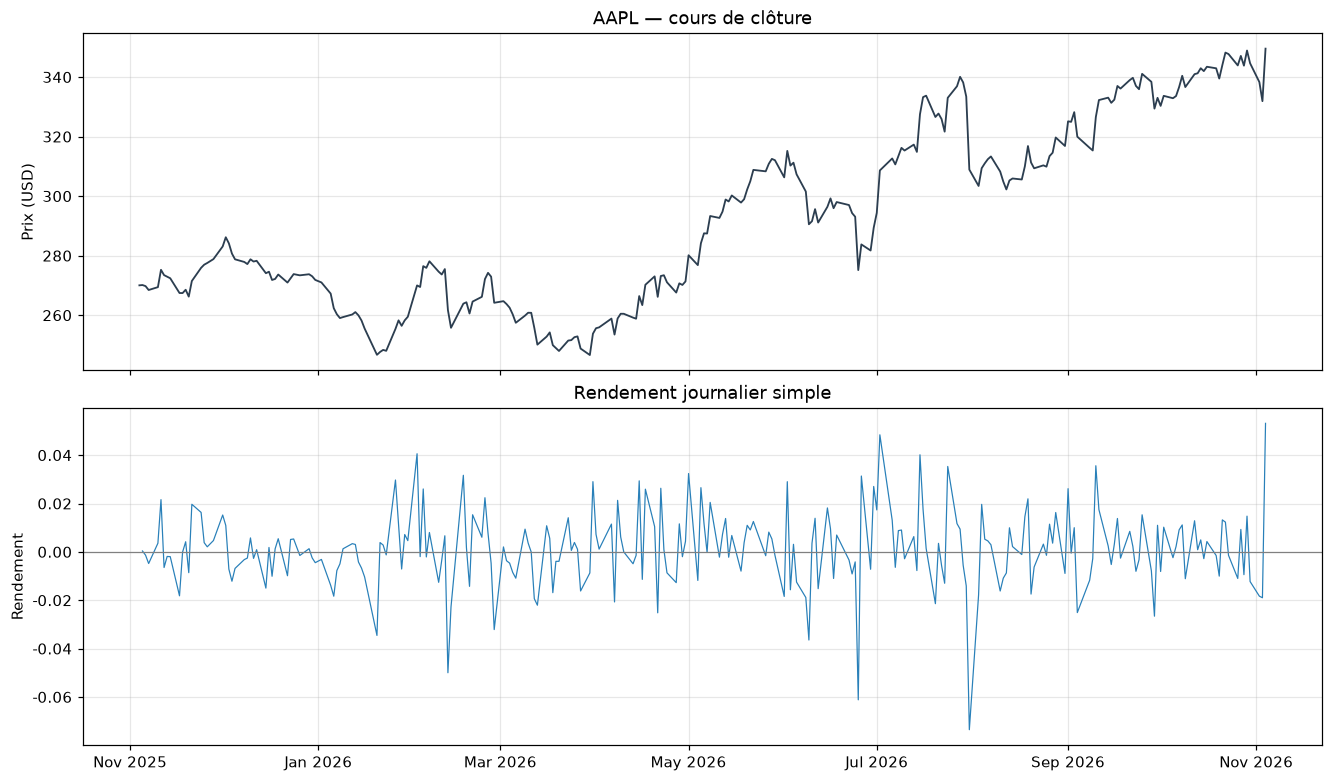

In [6]:
asset["ret_simple"] = asset["close"].pct_change()
asset["ret_log"] = np.log(asset["close"] / asset["close"].shift(1))
asset["ret_cum"] = (1 + asset["ret_simple"]).cumprod() - 1

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
axes[0].plot(asset.index, asset["close"], color="#2c3e50", linewidth=1.2)
axes[0].set_title(f"{SYMBOL} — cours de clôture")
axes[0].set_ylabel("Prix (USD)")

axes[1].plot(asset.index, asset["ret_simple"], color="#2980b9", linewidth=0.8)
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_title("Rendement journalier simple")
axes[1].set_ylabel("Rendement")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()


### Statistiques des rendements

La skewness et la kurtosis renseignent sur l'asymétrie et l'épaisseur des queues (les marchés financiers ont souvent des kurtosis > 3 = queues épaisses).

In [7]:
stats = asset[["ret_simple", "ret_log"]].describe().T
stats["skew"] = asset[["ret_simple", "ret_log"]].skew().values
stats["kurt"] = asset[["ret_simple", "ret_log"]].kurt().values  # kurtosis excédentaire (0 = normale)
stats


,count,mean,std,min,25%,50%,75%,max,skew,kurt
ret_simple,251.0000,0.0012,0.0156,-0.0735,-0.0075,0.0011,0.0094,0.0531,-0.3673,3.3416
ret_log,251.0000,0.0010,0.0157,-0.0764,-0.0075,0.0011,0.0094,0.0518,-0.4909,3.6733


## 6. Volatilité annualisée

On calcule l'écart-type glissant des rendements sur 20 et 60 jours, puis on
annualise en multipliant par $\sqrt{252}$ (nombre approximatif de séances
boursières par an).


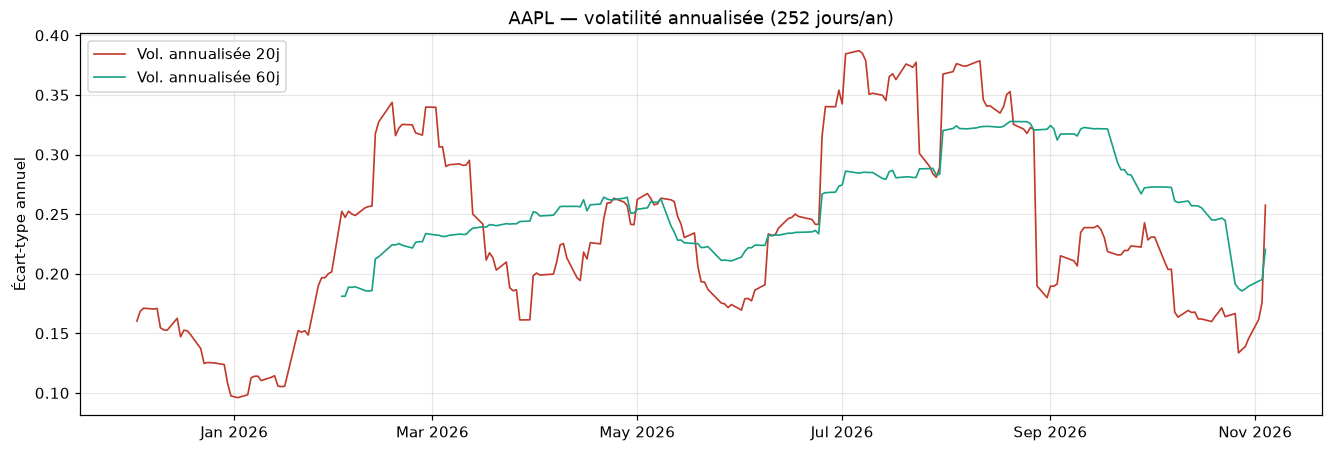

In [8]:
asset["vol_20"] = asset["ret_simple"].rolling(20).std() * np.sqrt(252)
asset["vol_60"] = asset["ret_simple"].rolling(60).std() * np.sqrt(252)

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(asset.index, asset["vol_20"], label="Vol. annualisée 20j", color="#c0392b", linewidth=1.1)
ax.plot(asset.index, asset["vol_60"], label="Vol. annualisée 60j", color="#16a085", linewidth=1.1)
ax.set_title(f"{SYMBOL} — volatilité annualisée (252 jours/an)")
ax.set_ylabel("Écart-type annuel")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()


## 7. RSI(14) — *Relative Strength Index*

Indicateur de momentum borné entre 0 et 100 :
- **> 70** : zone de surachat (potentiel retournement baissier).
- **< 30** : zone de survente (potentiel retournement haussier).

On utilise le **lissage de Wilder** (moyenne exponentielle avec
$\alpha = 1/\text{période}$), qui est la formule canonique du RSI.


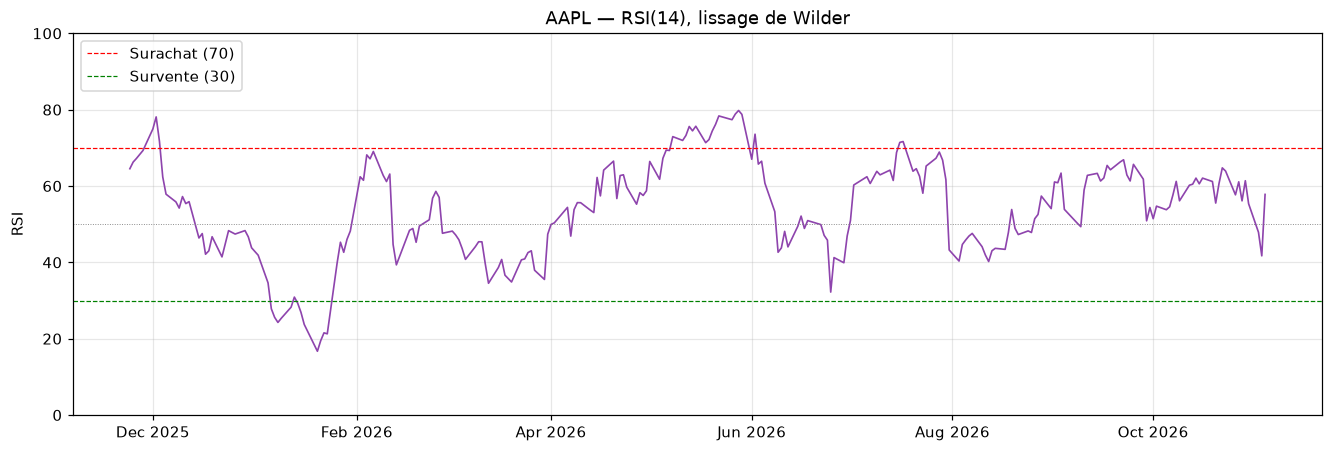

In [9]:
delta = asset["close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

period = 14
avg_gain = gain.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()

rs = avg_gain / avg_loss
asset["rsi_14"] = 100 - (100 / (1 + rs))

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(asset.index, asset["rsi_14"], color="#8e44ad", linewidth=1.1)
ax.axhline(70, color="red", linestyle="--", linewidth=0.8, label="Surachat (70)")
ax.axhline(30, color="green", linestyle="--", linewidth=0.8, label="Survente (30)")
ax.axhline(50, color="grey", linestyle=":", linewidth=0.6)
ax.set_title(f"{SYMBOL} — RSI(14), lissage de Wilder")
ax.set_ylabel("RSI")
ax.set_ylim(0, 100)
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()


## 8. Moyennes mobiles

- **SMA** (*Simple Moving Average*) 20/50/200 : moyenne arithmétique glissante.
  Le croisement SMA 50 / SMA 200 est le « golden cross » (haussier) ou « death
  cross » (baissier) classique.
- **EMA** (*Exponential Moving Average*) 12/26 : pondère davantage les valeurs
  récentes, sert de base au MACD.


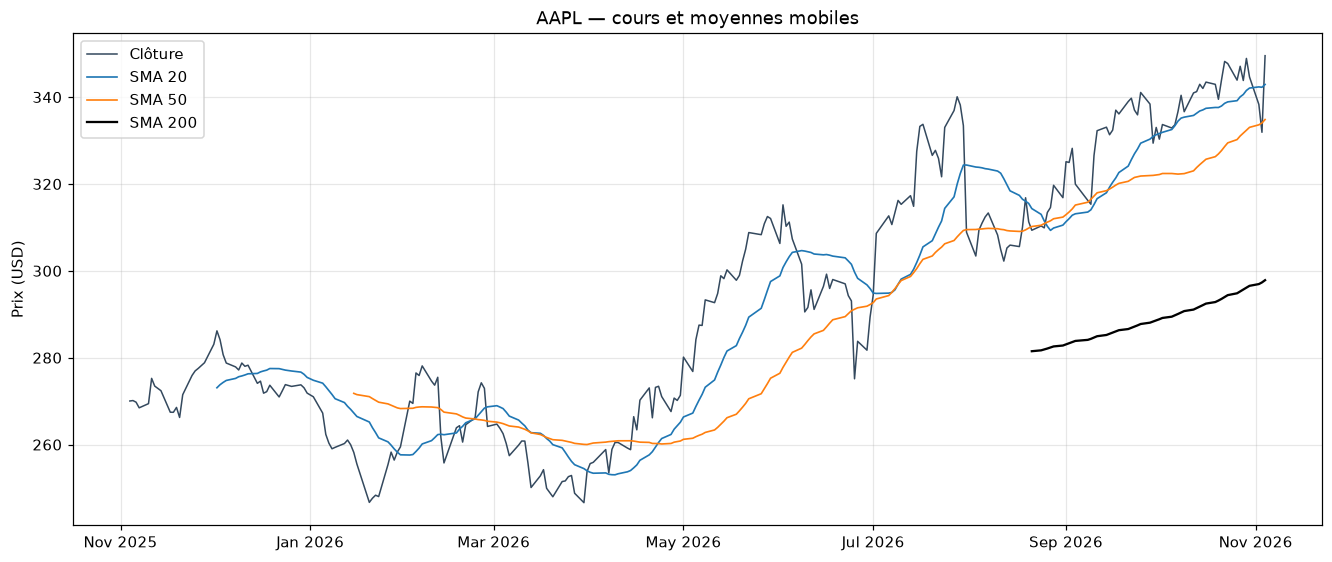

In [10]:
asset["sma_20"] = asset["close"].rolling(20).mean()
asset["sma_50"] = asset["close"].rolling(50).mean()
asset["sma_200"] = asset["close"].rolling(200).mean()
asset["ema_12"] = asset["close"].ewm(span=12, adjust=False).mean()
asset["ema_26"] = asset["close"].ewm(span=26, adjust=False).mean()

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.plot(asset.index, asset["close"], label="Clôture", color="#34495e", linewidth=1)
ax.plot(asset.index, asset["sma_20"], label="SMA 20", linewidth=1.1)
ax.plot(asset.index, asset["sma_50"], label="SMA 50", linewidth=1.1)
ax.plot(asset.index, asset["sma_200"], label="SMA 200", linewidth=1.5, color="black")
ax.set_title(f"{SYMBOL} — cours et moyennes mobiles")
ax.set_ylabel("Prix (USD)")
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()


## 9. MACD(12, 26, 9)

- **MACD** = EMA(12) − EMA(26) : écart entre la tendance court terme et long terme.
- **Signal** = EMA(9) du MACD.
- **Histogramme** = MACD − Signal : l'écart entre les deux. Un croisement
  ascendant de l'histogramme au-dessus de 0 est un signal d'achat classique.


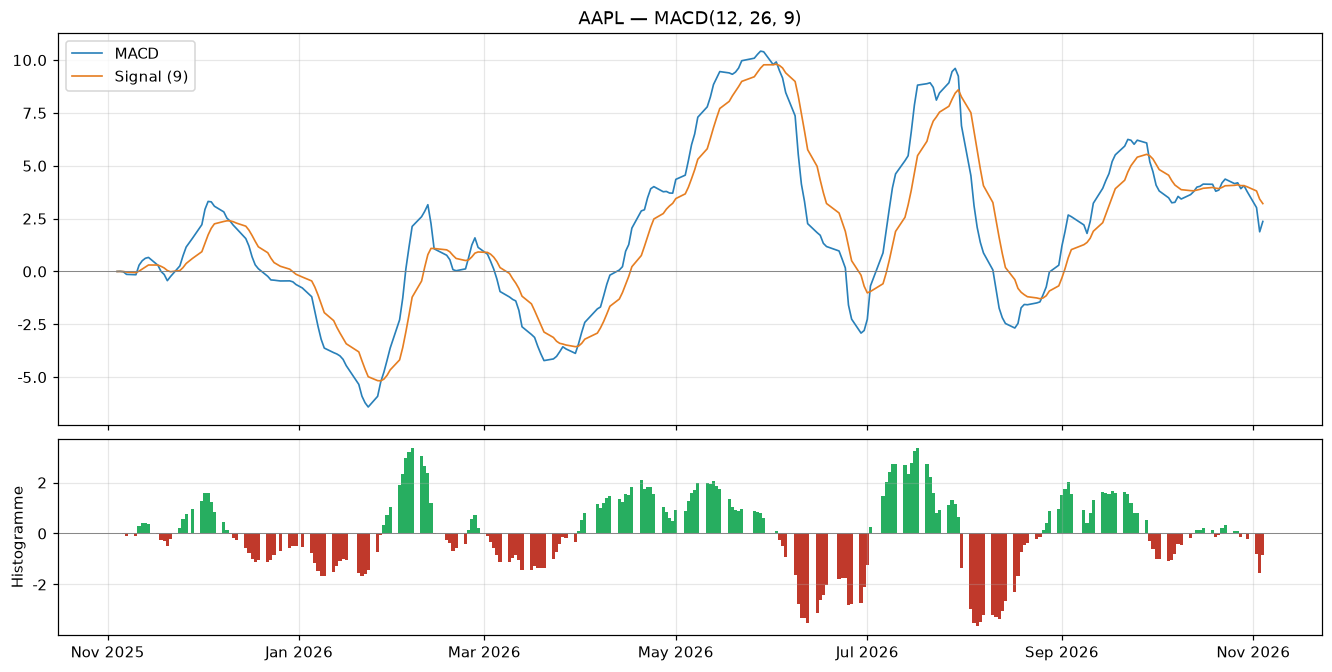

In [11]:
asset["macd"] = asset["ema_12"] - asset["ema_26"]
asset["macd_signal"] = asset["macd"].ewm(span=9, adjust=False).mean()
asset["macd_hist"] = asset["macd"] - asset["macd_signal"]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True,
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(asset.index, asset["macd"], label="MACD", color="#2980b9", linewidth=1.1)
axes[0].plot(asset.index, asset["macd_signal"], label="Signal (9)", color="#e67e22", linewidth=1.1)
axes[0].axhline(0, color="grey", linewidth=0.6)
axes[0].set_title(f"{SYMBOL} — MACD(12, 26, 9)")
axes[0].legend(loc="upper left")

colors = ["#27ae60" if v >= 0 else "#c0392b" for v in asset["macd_hist"]]
axes[1].bar(asset.index, asset["macd_hist"], color=colors, width=1.0)
axes[1].axhline(0, color="grey", linewidth=0.6)
axes[1].set_ylabel("Histogramme")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()


## 10. Comparaison multi-actifs : corrélation des rendements

On met les cours de clôture en colonnes (un actif par colonne), on calcule les
rendements journaliers, puis la matrice de corrélation. Une corrélation proche
de 1 indique des actifs qui évoluent ensemble (utile pour la diversification :
on cherche plutôt des corrélations faibles ou négatives).


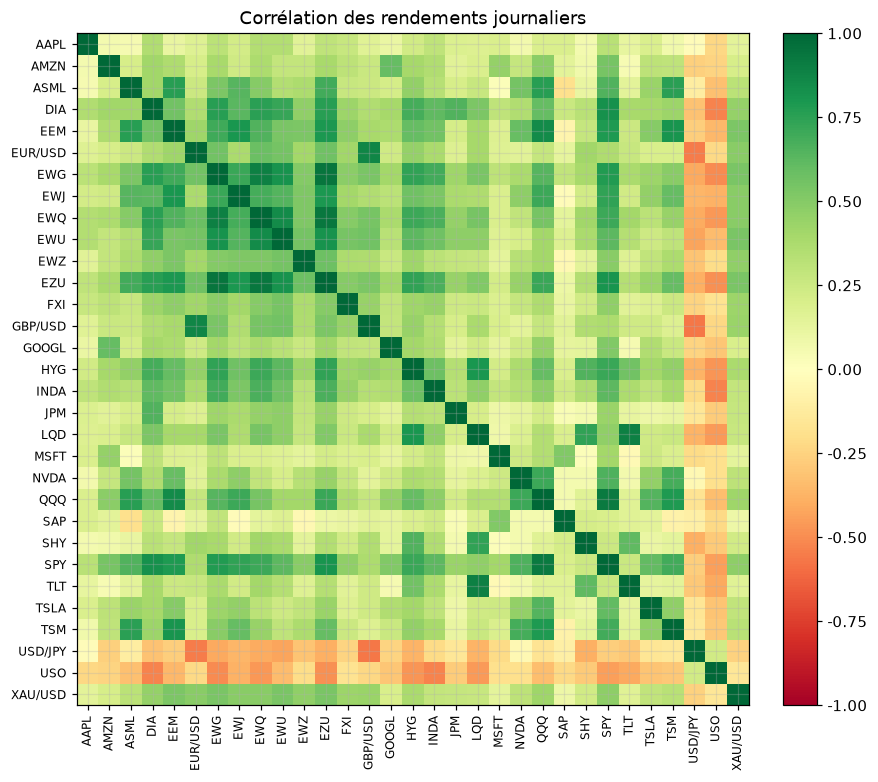

In [12]:
piv = (df.pivot_table(index="date", columns="symbol", values="close")
         .sort_index())
# On ne garde que les actifs ayant au moins 60 séances pour une corrélation fiable.
keep = piv.columns[piv.count() >= 60]
piv = piv[keep]
rets = piv.pct_change().dropna()
corr = rets.corr()

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
im = ax.imshow(corr, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.index, fontsize=8)
ax.set_title("Corrélation des rendements journaliers")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


## 11. Synthèse pour l'actif étudié

In [13]:
resume = pd.DataFrame({
    "Valeur": [
        len(asset),
        f"{asset.index.min().date()} → {asset.index.max().date()}",
        float(asset["ret_simple"].mean() * 252),
        float(asset["ret_simple"].std() * np.sqrt(252)),
        float(asset["vol_20"].mean()),
        float(asset["rsi_14"].dropna().iloc[-1]),
        float(asset["ret_cum"].dropna().iloc[-1]),
    ]
}, index=[
    "Nombre de séances",
    "Période",
    "Rendement moyen annualisé",
    "Volatilité annualisée",
    "Vol 20j (moyenne)",
    "RSI(14) dernière valeur",
    "Rendement cumulé total",
])
resume


,Valeur
Nombre de séances,252
Période,2025-11-04 → 2026-11-04
Rendement moyen annualisé,0.2899
Volatilité annualisée,0.2479
Vol 20j (moyenne),0.2357
RSI(14) dernière valeur,57.7990
Rendement cumulé total,0.2944


## 12. Conclusion et prochaines étapes

**Ce qu'on a établi :**
- Les données `price_history` se chargent proprement et couvrent ~1 an de
  cotations journalières (OHLCV) pour 31 actifs.
- Les indicateurs techniques de base (rendements, volatilité, RSI, moyennes
  mobiles, MACD) se calculent sans difficulté à partir de pandas.
- La matrice de corrélation montre que les ETF d'un même marché (ex. Europe)
  sont fortement corrélés entre eux — un point important pour la diversification
  du portefeuille.

**Prochaines étapes (hors périmètre de ce notebook) :**
1. Tester la stationnarité des rendements (test de Dickey-Fuller augmenté).
2. Étudier l'autocorrélation et la volatilité conditionnelle (ARCH/GARCH).
3. Préparer les *features* pour un premier modèle de prédiction simple
   (régression linéaire, puis modèles plus avancés).
4. Comparer les indicateurs entre actifs conventionnels et non conventionnels
   une fois le module stress testing avancé.

> Rappel : ce notebook est **exploratoire**, sans modèle entraîné. Toute
> prédiction viendra dans un module dédié, après validation de l'équipe.
